<a href="https://colab.research.google.com/github/SriVarshiniD/NIE-ML2/blob/main/ML2Lab7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

First 5 rows of dataset:
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0                5.1               3.5                1.4               0.2
1                4.9               3.0                1.4               0.2
2                4.7               3.2                1.3               0.2
3                4.6               3.1                1.5               0.2
4                5.0               3.6                1.4               0.2

Dataset shape: (150, 4)


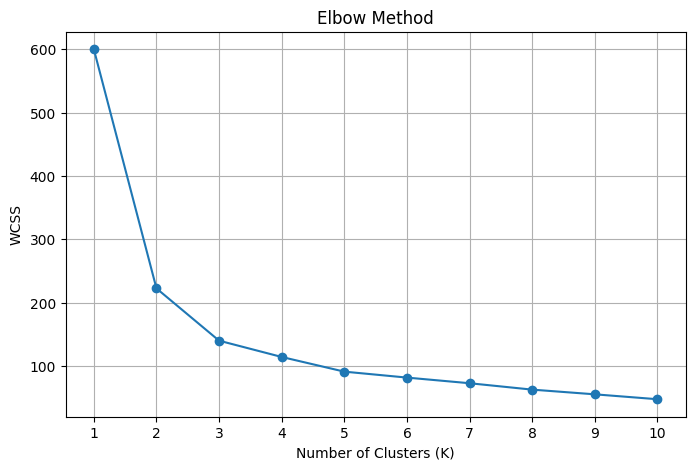


Clustered Dataset:
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   
5                5.4               3.9                1.7               0.4   
6                4.6               3.4                1.4               0.3   
7                5.0               3.4                1.5               0.2   
8                4.4               2.9                1.4               0.2   
9                4.9               3.1                1.5               0.1   

   Cluster  
0        1  
1        1  
2        1  
3        1  
4        1  
5        1  
6        1  
7     

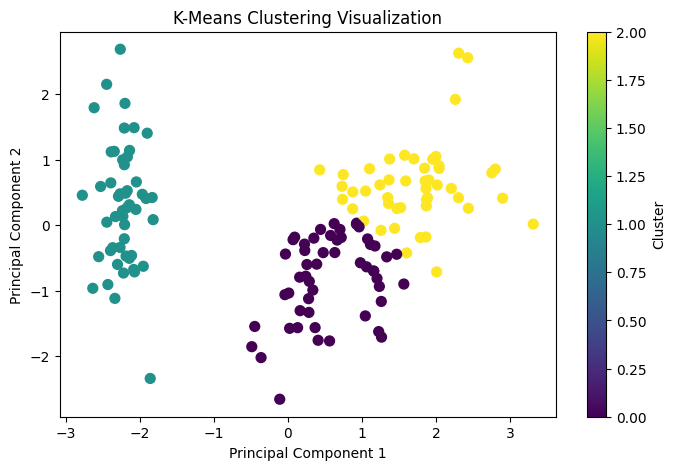

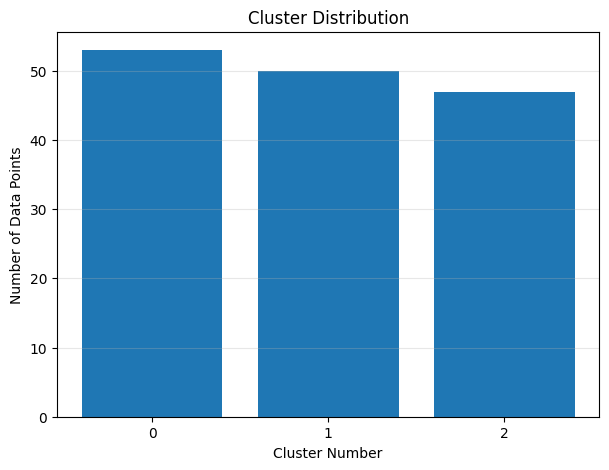


Final Cluster Counts:
Cluster 0 : 53 data points
Cluster 1 : 50 data points
Cluster 2 : 47 data points

K-Means Clustering Completed!


In [ ]:

# PROGRAM 7: K-MEANS CLUSTERING

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

# --------------------------------
# 1. LOAD DATASET
# --------------------------------

iris = load_iris()

X = pd.DataFrame(
    iris.data,
    columns=iris.feature_names
)

print("First 5 rows of dataset:")
print(X.head())

print("\nDataset shape:", X.shape)

# --------------------------------
# 2. DATA PREPROCESSING
# --------------------------------

# Standardize the dataset
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# --------------------------------
# 3. ELBOW METHOD
# --------------------------------

wcss = []

for k in range(1, 11):

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_scaled)

    wcss.append(kmeans.inertia_)

# Plot Elbow Graph
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, 11),
    wcss,
    marker='o'
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS")
plt.title("Elbow Method")

plt.xticks(range(1, 11))
plt.grid(True)

plt.show()

# --------------------------------
# 4. APPLY K-MEANS
# --------------------------------

kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

y_kmeans = kmeans.fit_predict(X_scaled)

# Add cluster labels to dataset
X['Cluster'] = y_kmeans

print("\nClustered Dataset:")
print(X.head(10))

# --------------------------------
# 5. PCA FOR 2D VISUALIZATION
# --------------------------------

pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

# Plot clusters
plt.figure(figsize=(8, 5))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=y_kmeans,
    cmap='viridis',
    s=50
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")

plt.title("K-Means Clustering Visualization")

plt.colorbar(label="Cluster")

plt.show()

# --------------------------------
# 6. CLUSTER DISTRIBUTION
# --------------------------------

cluster_counts = pd.Series(y_kmeans).value_counts().sort_index()

plt.figure(figsize=(7, 5))

plt.bar(
    cluster_counts.index,
    cluster_counts.values
)

plt.xlabel("Cluster Number")
plt.ylabel("Number of Data Points")

plt.title("Cluster Distribution")

plt.xticks([0, 1, 2])
plt.grid(axis='y', alpha=0.3)

plt.show()

# --------------------------------
# 7. DISPLAY FINAL RESULTS
# --------------------------------

print("\nFinal Cluster Counts:")

for cluster, count in cluster_counts.items():

    print(
        "Cluster", cluster,
        ":", count, "data points"
    )

print("\nK-Means Clustering Completed!")
